# DPDP clause classifier: a walk-through you can run

This notebook shows the whole pipeline working on a **practice split**, step by step.

**Read this first.** The data comes from `db/dev.db`. That is a practice copy of your database where 8 *training* policies were moved aside as a pretend test set. The labels are Claude's unreviewed suggestions. So every score here measures how well a program copies Claude's labelling. **None of these numbers goes in the paper.** The real numbers come later, from the 180 clauses your team labels by hand.

How to run it: press **Shift+Enter** on each cell, from the top. Run the cells in order.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# find the project folder (the one that contains src/) and work from there
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "src")) and os.path.dirname(root) != root:
    root = os.path.dirname(root)
os.chdir(root)
sys.path.insert(0, os.path.join(root, "src", "models"))

import classical as cls          # our real code from src/models/classical.py
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)

DB = "db/dev.db"                 # the PRACTICE database. Never put db/dpdp.db here.
assert os.path.exists(DB), "Run this first in PowerShell:  python src/models/make_dev_db.py"
assert os.path.basename(DB).lower() != "dpdp.db", "Use the practice copy, not the real database"
print("Project folder:", root)
print("Database:", DB)

Project folder: F:\dpdp-classifier
Database: db/dev.db


## 1. The data

Every clause has a label: which DPDP **obligation** it is about, and a **status** (satisfied or not_satisfied). Clauses that fit no rule are `None`.

`train` is what the programs learn from. `test` is the pretend exam they have never seen. The split is by *policy*, so clauses from one policy never sit on both sides.

train: 600 clauses from 40 policies
test : 120 clauses from 8 policies (practice only)


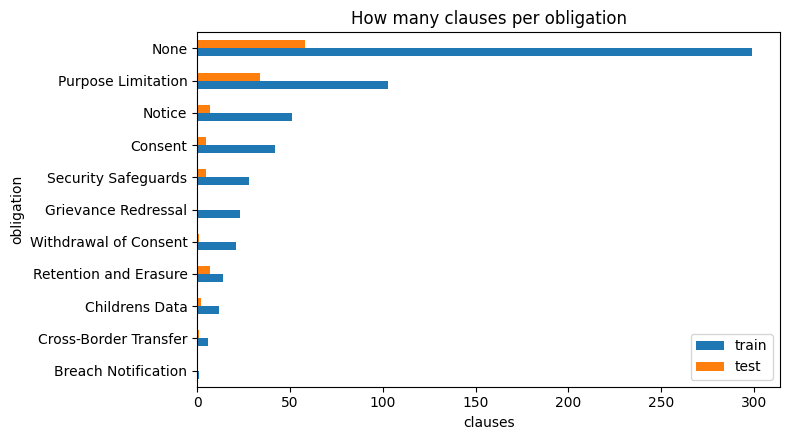

,train,test
obligation,,
None,299,58
Purpose Limitation,103,34
Notice,51,7
Consent,42,5
Security Safeguards,28,5
Grievance Redressal,23,0
Withdrawal of Consent,21,1
Retention and Erasure,14,7
Childrens Data,12,2


In [2]:
train = cls.load(DB, "train")
test  = cls.load(DB, "test")
print(f"train: {len(train)} clauses from {train.policy_id.nunique()} policies")
print(f"test : {len(test)} clauses from {test.policy_id.nunique()} policies (practice only)")

counts = pd.DataFrame({"train": train.obligation.value_counts(), "test": test.obligation.value_counts()}).fillna(0).astype(int)
counts = counts.sort_values("train")
ax = counts.plot.barh(figsize=(8, 4.5))
ax.set_title("How many clauses per obligation"); ax.set_xlabel("clauses")
plt.tight_layout(); plt.show()
display(counts.sort_values("train", ascending=False))

Notice how uneven it is. `None` and `Purpose Limitation` are common. `Breach Notification` has almost nothing. A program that has seen only one example of a rule cannot learn it. That is why the **macro-F1** score (which counts every label equally) is the main score, not accuracy.

In [ ]:
display(train.sample(6, random_state=1)[["clause_text", "obligation", "status"]])

## 2. Turning text into numbers (TF-IDF)

Programs cannot read words. TF-IDF gives every word or two-word phrase a number: **high** if the word is frequent in this clause but rare across all clauses, **low** if it appears everywhere (like "the"). Here is one clause and its highest-scoring words.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer(ngram_range=(1, 2), lowercase=True, min_df=2).fit(train.clause_text)
print("Words and two-word phrases the program knows:", len(vec.vocabulary_))

example = train[train.obligation == "Retention and Erasure"].clause_text.iloc[0]
row = vec.transform([example])
names = np.array(vec.get_feature_names_out())
top = np.argsort(row.toarray()[0])[::-1][:10]
print("\nClause:", example[:300], "...")
display(pd.DataFrame({"word / phrase": names[top], "TF-IDF score": row.toarray()[0][top].round(3)}))

Words and two-word phrases the program knows: 2977

Clause: We keep your personal information to enable your continued use of our Services, for as long as it is required in order to fulfil the relevant purposes described in this Policy, and, as may be required by law such as for tax and accounting purposes, or as otherwise communicated to you. ...


,word / phrase,TF-IDF score
0,as,0.301
1,required,0.185
2,purposes,0.172
3,communicated to,0.138
4,services for,0.138
5,required in,0.138
6,as may,0.138
7,and as,0.138
8,accounting,0.138
9,to fulfil,0.138


## 3. Choosing the setting for the SVM (cross-validation)

An SVM has a setting called **C** (how strictly it fits the training data). We try 5 values. For each, the training policies are cut into 5 groups. The program learns from 4 groups and is scored on the 5th, five times. This is `GroupKFold`: clauses of one policy always stay together.

The test set is not used here at all.

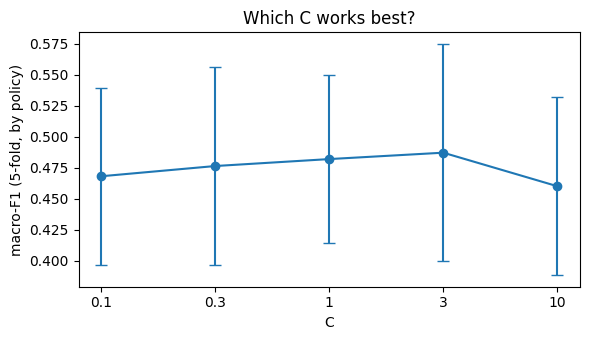

Best C on the training folds: 3


In [4]:
from sklearn.model_selection import GroupKFold
y = train.obligation.values; X = train.clause_text.values; g = train.policy_id.values
folds = list(GroupKFold(n_splits=5).split(X, y, g))
Cs = [0.1, 0.3, 1, 3, 10]
means, stds = [], []
for c in Cs:
    s = []
    for tr, va in folds:
        m = cls.svm_pipe(c).fit(X[tr], y[tr])
        s.append(cls.macro_f1(y[va], m.predict(X[va])))
    means.append(np.mean(s)); stds.append(np.std(s))
plt.figure(figsize=(6, 3.5))
plt.errorbar(range(len(Cs)), means, yerr=stds, marker="o", capsize=4)
plt.xticks(range(len(Cs)), Cs); plt.xlabel("C"); plt.ylabel("macro-F1 (5-fold, by policy)")
plt.title("Which C works best?"); plt.tight_layout(); plt.show()
best_C = Cs[int(np.argmax(means))]
print("Best C on the training folds:", best_C)

## 4. Train the models

- **SVM**: finds a boundary between labels in the TF-IDF number space.
- **Random Forest**: 300 decision trees that vote.
- **Majority baseline**: always says the most common label. Any real model must beat it.
- **Keyword baseline**: looks for words like *breach*, *withdraw*, *retain*. Any real model should beat it too.

Both models use *class weights*, so rare labels count more during training.

In [5]:
bp_path = "runs/dev/best_params_obligation.json"
if os.path.exists(bp_path):
    bp = json.load(open(bp_path))["best_params"]
    rf_par = bp["rf"]; print("Random Forest setting from your earlier tuning run:", rf_par)
else:
    rf_par = {"n": 300, "depth": None, "leaf": 2}; print("No tuning file found, using a default Random Forest setting:", rf_par)

svm = cls.svm_pipe(best_C).fit(train.clause_text.values, train.obligation.values)
rf  = cls.rf_pipe(rf_par["n"], rf_par["depth"], rf_par["leaf"]).fit(train.clause_text.values, train.obligation.values)
majority_label = train.obligation.mode()[0]
status_major = train.status.mode()[0]
print("Models trained. Majority label is:", majority_label)

Random Forest setting from your earlier tuning run: {'n': 300, 'depth': None, 'leaf': 2}
Models trained. Majority label is: None


## 5. Score them on the practice test

Macro-F1 goes from 0 to 1. The **95% range** tells you how much the score could move with a different sample of policies. If two ranges overlap, treat the systems as tied.

,system,macro-F1,95% low,95% high,accuracy
0,majority baseline,0.072,0.064,0.119,0.483
1,keyword baseline,0.305,0.249,0.401,0.567
2,SVM,0.477,0.351,0.576,0.700
3,Random Forest,0.292,0.211,0.506,0.642


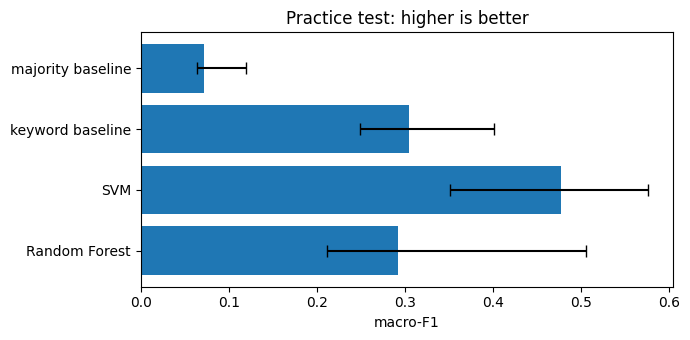

In [6]:
yte = test.obligation.values; pol = test.policy_id.values
preds = {
    "majority baseline": np.array([majority_label] * len(test)),
    "keyword baseline":  np.array(cls.keyword_predict(test.clause_text.values, status_major)),
    "SVM":               svm.predict(test.clause_text.values),
    "Random Forest":     rf.predict(test.clause_text.values),
}
from sklearn.metrics import accuracy_score
rows = []
for name, p in preds.items():
    lo, hi = cls.boot_ci(yte, p, pol)
    rows.append({"system": name, "macro-F1": cls.macro_f1(yte, p), "95% low": lo, "95% high": hi, "accuracy": accuracy_score(yte, p)})
res = pd.DataFrame(rows).round(3)
display(res)

plt.figure(figsize=(7, 3.5))
err = [res["macro-F1"] - res["95% low"], res["95% high"] - res["macro-F1"]]
plt.barh(res.system, res["macro-F1"], xerr=err, capsize=4)
plt.xlabel("macro-F1"); plt.title("Practice test: higher is better"); plt.gca().invert_yaxis()
plt.tight_layout(); plt.show()

## 6. Which obligations does each model find?

F1 for each obligation. Obligations with very few test clauses (see `n`) give shaky numbers, so read this chart with care.

,n (test),SVM,Random Forest
Breach Notification,0,0.00,0.00
Childrens Data,2,0.80,0.00
Consent,5,0.25,0.14
Cross-Border Transfer,1,0.00,0.00
Grievance Redressal,0,0.00,0.00
None,58,0.83,0.80
Notice,7,0.47,0.50
Purpose Limitation,34,0.64,0.53
Retention and Erasure,7,0.44,0.44
Security Safeguards,5,0.67,0.50


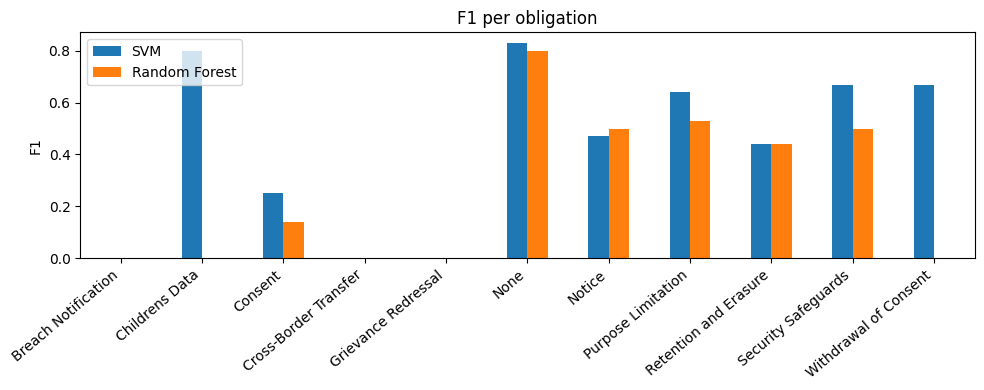

In [7]:
from sklearn.metrics import f1_score
labels = sorted(set(yte) | set(train.obligation))
per = pd.DataFrame({
    "n (test)": [int((yte == l).sum()) for l in labels],
    "SVM": f1_score(yte, preds["SVM"], labels=labels, average=None, zero_division=0),
    "Random Forest": f1_score(yte, preds["Random Forest"], labels=labels, average=None, zero_division=0),
}, index=labels).round(2)
display(per)
per[["SVM", "Random Forest"]].plot.bar(figsize=(10, 4)); plt.ylabel("F1"); plt.title("F1 per obligation")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

## 7. Where does the SVM go wrong?

The confusion matrix: each row is the **true** label, each column is what the SVM **predicted**. A perfect model has numbers only on the diagonal.

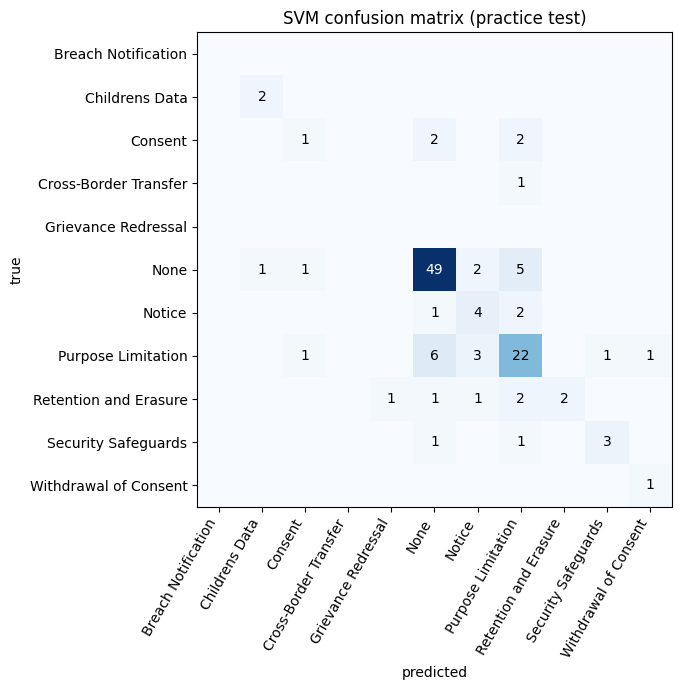

In [8]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(yte, preds["SVM"], labels=labels)
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=60, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha="center", va="center", color="black" if cm[i, j] < cm.max() / 2 else "white")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("SVM confusion matrix (practice test)")
plt.tight_layout(); plt.show()

In [9]:
wrong = test.assign(predicted=preds["SVM"])
wrong = wrong[wrong.obligation != wrong.predicted]
print(f"The SVM got {len(wrong)} of {len(test)} wrong. Eight of them:")
display(wrong.sample(min(8, len(wrong)), random_state=3)[["clause_text", "obligation", "predicted"]].rename(columns={"obligation": "true"}))

The SVM got 36 of 120 wrong. Eight of them:


,clause_text,true,predicted
17,Access to the Near field Communication (NFC) chip on device to enable tap to pay functionality.,None,Purpose Limitation
97,The Swiggy Group disclaims any liability or responsibility with respect to how restaurants/merchants share and/or use your information provided to them.,None,Purpose Limitation
78,"Mobile device IDs: Unique mobile device identifier (e.g. IDFA or other device IDs on Apple devices like the iPhone and iPad), if you're using our Services o...",None,Notice
86,The third party service providers providing payment gateway and payment processing services are all validated as compliant with the payment card industry st...,Security Safeguards,Purpose Limitation
74,You can send your data deletion request to us through email.,Retention and Erasure,Grievance Redressal
91,"Applications: If you use the Platforms, we may collect information about the presence and/or absence and/or details pertaining to other applications on your...",None,Notice
67,"User Communications: When you send email or other communication to us, we may retain those communications in order to process your inquiries, respond to you...",Retention and Erasure,Purpose Limitation
98,We encourage you to review their privacy policy and other terms and conditions to understand their use of your information better.,None,Purpose Limitation


Read these. Some mistakes are the program's fault. Others are clauses where the *label* is arguable. Sorting the mistakes into those two kinds is the error analysis in the paper.

## 8. What did the SVM learn?

For each obligation, the words that push the SVM toward it. If these look sensible (*breach*, *retain*, *withdraw*), the model is learning real signals. If they are odd, something is wrong.

In [10]:
tf = svm.named_steps["tfidf"]; clf = svm.named_steps["clf"]
feats = np.array(tf.get_feature_names_out())
out = {}
for i, cl in enumerate(clf.classes_):
    out[cl] = ", ".join(feats[np.argsort(clf.coef_[i])[::-1][:8]])
display(pd.DataFrame({"top words": out}))

,top words
Breach Notification,"suspected, notify you, notify, you about, data security, any applicable, required to, breach"
Childrens Data,"child, parents, children, platform is, minor, be used, guardians, used by"
Consent,"consent, your consent, with your, your, you, the terms, agree, have the"
Cross-Border Transfer,"mechanisms, transfer, transfers, the applicable, transfer your, india, outside of, outside"
Grievance Redressal,"officer, com, concerns, us at, complaints, be the, 18, reach out"
None,"cookies, that, to you, how, cookie, that the, shall, our privacy"
Notice,"collect, the user, device, account, about you, including, also collect, information"
Purpose Limitation,"necessary, use your, use the, payment, third parties, sell, to, parties"
Retention and Erasure,"retention, periods, period, period of, retain, retained for, retained, deleted"
Security Safeguards,"security, secure, industry, protect, access, security of, unauthorised, to protect"


## 9. Try your own clause

Edit the text below and run the cell. The SVM shows its top three guesses.

In [11]:
my_clause = "You may withdraw your consent at any time by writing to privacy@example.com and we will stop processing your data."

def guess(text, k=3):
    s = svm.decision_function([text])[0]
    order = np.argsort(s)[::-1][:k]
    return [(clf.classes_[i], round(float(s[i]), 2)) for i in order]

print("SVM top guesses:", guess(my_clause))
print("Random Forest says:", rf.predict([my_clause])[0])
print("Keyword baseline says:", cls.keyword_predict([my_clause], status_major)[0])

SVM top guesses: [('Withdrawal of Consent', 0.41), ('Consent', -0.57), ('Grievance Redressal', -0.7)]
Random Forest says: Consent
Keyword baseline says: Consent


## 10. One model or two? (the open question in the paper)

The paper asks whether to predict obligation and status in **one combined label** (a joint model) or with **two models** (one for the obligation, one for the status). Here are both on the practice test.

In [12]:
# two models: obligation model (above) + a status model trained on non-None clauses
tr_nn = train[train.obligation != "None"]
st_path = "runs/dev/best_params_status.json"
st_C = json.load(open(st_path))["best_params"]["svm"]["C"] if os.path.exists(st_path) else 1
status_model = cls.svm_pipe(st_C).fit(tr_nn.clause_text.values, tr_nn.status.values)

obl_pred = preds["SVM"]
st_pred = status_model.predict(test.clause_text.values)
two_model = np.array([o + "|" + ("not_applicable" if o == "None" else s) for o, s in zip(obl_pred, st_pred)])

joint_model = cls.svm_pipe(1).fit(train.clause_text.values, train.joint.values)
one_model = joint_model.predict(test.clause_text.values)

yj = test.joint.values
print("Two separate models  -> joint macro-F1: %.3f" % cls.macro_f1(yj, two_model))
print("One combined model   -> joint macro-F1: %.3f" % cls.macro_f1(yj, one_model))

Two separate models  -> joint macro-F1: 0.318
One combined model   -> joint macro-F1: 0.437


If the two-model version is better, that is a reason to use it in the paper. Decide this **before** the real run, from the training-only cross-validation, never from the real test set.

## 11. Gemini, side by side

Gemini is not trained. It is given the rubric as instructions and labels each clause. Once you have run `gemini_runner.py` and `compare.py`, their tables show up here.

In [13]:
import glob
found = sorted(glob.glob("runs/report*/table2_obligation.csv"))
if not found:
    print("No comparison table yet. Run gemini_runner.py and compare.py first (see the guide).")
for f in found:
    print("\n", f)
    display(pd.read_csv(f).round(3))
print("\nIf the gemini rows come from --mock, they are fake and mean nothing.")

No comparison table yet. Run gemini_runner.py and compare.py first (see the guide).

If the gemini rows come from --mock, they are fake and mean nothing.


## What changes for the real run

Nothing in the code. After your team labels the 180 test clauses and the labels are frozen, you run the same scripts without `--dev`, on `db/dpdp.db`:

1. `load_labels.py test ...`, then `adjudicate`, then create `data/labels/LOCKED`.
2. `classical.py cv`, then `classical.py final` for each target.
3. `gemini_runner.py` (3 runs) and `compare.py`.

This notebook is for understanding and demos. The numbers for the paper come only from those real runs.